In [ ]:
import sys; sys.path.append("..")      # para que el notebook encuentre src/
from collections import Counter
from src.fasta import procesar_fasta

cont = Counter()
df = next(procesar_fasta("../data/muestra.fasta", tam_lote=100, contadores=cont))
df.head()


,id_original,te_class,te_order,te_superfamily,especie,secuencia,longitud,porcentaje_gc,porcentaje_n
0,PDB00000001,CLASSII,HELITRON,HELITRON,Halicephalobus mephisto,AAAAAACAAAAGAACTTAAATTTTTTAAAATTTCAATATAAAAAAA...,1991,31.5419,0.0
1,PDB00000002,CLASSII,HELITRON,HELITRON,Halicephalobus mephisto,TTTAAATAATAAATTTTTATTTTTAAAATTATAAAATTAATTTTTA...,1689,31.5571,0.0
2,PumCon-1.11,CLASSI,SINE,TRNA,Puma concolor,GGGGCGCCTGGGTGGCTCAGTCGGTTAAGCGTCCGACTCTTGATTT...,235,51.0638,0.0
3,PumCon-1.141,CLASSII,TIR,TC1MARINER,Puma concolor,CAGTTGACCCTTGAACAACACGGGTTTGAACTGCGCGGGTCCACTT...,340,39.7059,0.0
4,PumCon-1.14,CLASSI,SINE,TRNA,Puma concolor,GGGGCGCCTGGGTGGCTCAGTCGGTTAAGCGTCCGACTTCGGCTCA...,233,52.7897,0.0


In [2]:
import time
cont = Counter()
t0 = time.perf_counter()
n, especies, superfam, con_n, suma_n = 0, set(), set(), 0, 0
lmin, lmax = float("inf"), 0

for df in procesar_fasta("../data/PanTEon_Database_v1.6.1.fasta", 5000, cont):
    n += len(df)
    especies.update(df.especie); superfam.update(df.te_order + "/" + df.te_superfamily)
    con_n += (df.porcentaje_n > 0).sum()
    suma_n += df.secuencia.str.count("N").sum()
    lmin, lmax = min(lmin, df.longitud.min()), max(lmax, df.longitud.max())

print(cont)
print(n, len(especies), len(superfam), con_n, suma_n, lmin, lmax)
print(f"{time.perf_counter() - t0:.1f} s")

Counter({'leidos': 239946, 'validos': 239946})
239946 2790 65 54837 2147161 81 19926
32.7 s


In [1]:
from pymongo import MongoClient

cliente= MongoClient("mongodb://localhost:27017", serverSelectionTimeoutMS=3000)
print(cliente.admin.command("ping"))

db= cliente["panteon"]

{'ok': 1.0}


## Configuración inicial y librerías
Se importa pandas y se definen las rutas de los archivos

In [2]:
import pandas as pd

columnas =['Kingdom','Phylum','Class','Order','Family','Species','Source','Source 2','Notes']
nulos =['NA','N/A','','-']


ruta_default_csv ="PanTEon_Database_metadata_v1.6.1.csv"
ruta_default_fasta ="PanTEon_Database_v1.6.1.fasta"


## Leer y limpiar el csv
Funciones para leer el CSV con la taxonomía, para cambiarle los nombres a las columnas en español y quitar filas vacías que dañen el análisis.   

In [4]:

def leer_csv(ruta):
    try:
        especies_df =pd.read_csv(ruta,usecols=columnas,na_values=nulos)

        columnas_texto = especies_df.select_dtypes(
            include=["object", "string"]
        ).columns

        for columna in columnas_texto:
            especies_df[columna] =(especies_df[columna].str.strip().str.replace(r"\s+", " ", regex=True))

        return especies_df
    except FileNotFoundError:
        print(f"No se encontró el archivo '{ruta}'.")
    except pd.errors.ParserError:
        print(f"N se pudo interpretar el csv '{ruta}'.")
    except Exception as e:
        print(f"error inesperado al leer el csv: {e}")

def renombrar_columnas(especies_df):
    especies_df_renombrado =especies_df.rename(
        columns={
            'Kingdom':'reino',
            'Phylum':'filo',
            'Class':'tax_clase',
            'Order':'tax_orden',
            'Family':'familia',
            'Species':'especie',
            'Source':'fuente',
            'Source 2':'fuente_2',
            'Notes': 'notas'
        }
    )

    return especies_df_renombrado

def tratar_faltantes(especies_df):
    especies_df_limpio =especies_df.copy()
    especies_df_limpio =especies_df_limpio.dropna(subset=['especie'])

    especies_df_limpio  =especies_df_limpio.astype(object).where(especies_df_limpio.notna(),None)

    return especies_df_limpio



# Funciones del fasta y cruce
Funciones para leer el fasta y comparar los datos.

In [5]:
def leer_especies_fasta(ruta):
    especies ={}
    total_encabezados =0
    sin_especie =[]

    with open(ruta, "r",encoding="utf-8") as archivo:
        for linea in archivo:
            if not linea.startswith(">"):
                continue

            total_encabezados += 1
            cabecera = linea[1:].strip()

            if "@" not in cabecera:
                sin_especie.append(cabecera)
                continue

            nombre =cabecera.rsplit("@",1)[-1].strip()
            clave =normalizar_especie(nombre)

            if clave is None:
                sin_especie.append(cabecera)
                continue

            if clave not in especies:
                especies[clave] ={"nombres":[],"conteo":0}

            if nombre not in especies[clave]["nombres"]:
                especies[clave]["nombres"].append(nombre)

            especies[clave]["conteo"] +=1

    return especies,total_encabezados,sin_especie


def cruzar(df, especies_fasta):
    csv ={}

    for nombre in df["especie"]:
        clave =normalizar_especie(nombre)
        if clave is None:
            continue
        if clave not in csv:
            csv[clave] =[]
        csv[clave].append(nombre)

    claves_csv =set(csv)
    claves_fasta =set(especies_fasta)

    ambos =claves_csv & claves_fasta
    solo_fasta =claves_fasta-claves_csv
    solo_csv =claves_csv-claves_fasta

    return ambos,solo_fasta,solo_csv, csv


def reportar_cruce(ambos, solo_fasta, solo_csv, csv, fasta, total_encabezados, sin_especie, filas_csv):
    print("Filas del csv:",filas_csv)
    print("Especies distintas en el csv:",len(csv))
    print("Encabezados en el fasta:",total_encabezados)
    print("Encabezados sin especie:",len(sin_especie))
    print("Especies distintas en el fasta:",len(fasta))
    print("En los dos:", len(ambos))
    print("Solo en el fasta:",len(solo_fasta))
    print("Solo en el csv:",len(solo_csv))

## Correr las funciones para el csv
Se carga el csv, se renombran columnas y se limpian los nulos.   

In [7]:
especies =leer_csv(ruta_default_csv)
especies =renombrar_columnas(especies)
especies =tratar_faltantes(especies)

## Normalización de nombres

Esta función quita espacios al principio, al final y espacios repetidos de por medio, pasa todo a minúsculas y arregla algunas abreviaturas para que coincidan el csv y el fasta.

In [8]:
def normalizar_especie(nombre):
    if pd.isna(nombre):
        return None

    nombre = str(nombre).strip().lower()
    nombre = " ".join(nombre.split())

    abreviaturas = ["subsp.", "sp.", "var.", "f."]
    palabras = nombre.split()

    for i in range(len(palabras)):
        if palabras[i] in abreviaturas:
            palabras[i] = palabras[i][:-1]

    nombre = " ".join(palabras)

    return nombre or None


## Comparar el csv con el fasta
Se revisa si los nombres de las especies coinciden exactamente entre ambos archivos y si hay diferencias, se reemplazan las del csv por las del fasta 

In [9]:
def revisar_diferencias(ambos, csv, fasta):
    for clave in sorted(ambos):
        nombres_csv =csv[clave]
        nombres_fasta =fasta[clave]["nombres"]
        if not (set(nombres_csv) & set(nombres_fasta)):
            print("csv:", nombres_csv," - fasta",nombres_fasta," - ",fasta[clave]["conteo"],"secuencias")


def reemplazar_nombres(especies, fasta):
    reemplazos =[]
    nombres_nuevos =[]
    for nombre in especies["especie"]:
        clave = normalizar_especie(nombre)
        nombres_fasta = fasta[clave]["nombres"]
        assert len(nombres_fasta)==1
        if nombre in nombres_fasta:
            nombres_nuevos.append(nombre)
        else:
            reemplazos.append((nombre, nombres_fasta[0]))
            nombres_nuevos.append(nombres_fasta[0])

    especies["especie"] = nombres_nuevos
    print(reemplazos)

    return especies

## Ejecutar el cruce y mostrar resultados
Se corren las funciones para leer y cruzar y el print nos muestra cuántas especies hay en cada lado, los iguales y las diferencias de nombres que tocó ajustar.   

In [10]:
fasta,total_encabezados,sin_especie =leer_especies_fasta(ruta_default_fasta)
ambos,solo_fasta,solo_csv,csv = cruzar(especies,fasta)

reportar_cruce(ambos, solo_fasta,solo_csv,csv,fasta,total_encabezados,sin_especie,len(especies))
revisar_diferencias(ambos,csv,fasta)
especies =reemplazar_nombres(especies,fasta)

Filas del csv: 2790
Especies distintas en el csv: 2790
Encabezados en el fasta: 239946
Encabezados sin especie: 0
Especies distintas en el fasta: 2790
En los dos: 2790
Solo en el fasta: 0
Solo en el csv: 0
csv: ['Abrus pulchellus subsp cantoniensis']  - fasta ['Abrus pulchellus subsp. cantoniensis']  -  178 secuencias
csv: ['Beta vulgaris subsp vulgaris']  - fasta ['Beta vulgaris subsp. vulgaris']  -  296 secuencias
csv: ['Coccomyxa sp obi']  - fasta ['Coccomyxa sp. obi']  -  11 secuencias
csv: ['Marchantia polymorpha subsp montivagans']  - fasta ['Marchantia polymorpha subsp. montivagans']  -  48 secuencias
[('Abrus pulchellus subsp cantoniensis', 'Abrus pulchellus subsp. cantoniensis'), ('Beta vulgaris subsp vulgaris', 'Beta vulgaris subsp. vulgaris'), ('Coccomyxa sp obi', 'Coccomyxa sp. obi'), ('Marchantia polymorpha subsp montivagans', 'Marchantia polymorpha subsp. montivagans')]


## Guardar en la base de datos

Se limpia la colección anterior en MongoDB y se mete todo el dataframe ya procesado como documentos nuevos.

In [11]:
def cargar_especies(especies_df, db):
    coleccion =db["especies"]

    documentos = especies_df.to_dict(orient="records")

    coleccion.delete_many({})

    if documentos:
        coleccion.insert_many(documentos)

cargar_especies(especies, db)

## 1. Configuración del entorno y conexión a MongoDB

En esta etapa se importan las bibliotecas y los módulos necesarios para ejecutar el pipeline de cálculo de *k-mers*. Además, se establece la conexión con la base de datos que contiene las secuencias y se configuran los índices de la colección donde se almacenarán los resultados.

### Importación de dependencias

Se utilizan las siguientes bibliotecas y módulos:

- **`sys`**: permite modificar la ruta de búsqueda de módulos de Python mediante `sys.path.append("..")`, facilitando la importación de módulos ubicados en el directorio `src/`.
- **`time`**: proporciona funciones para medir intervalos de tiempo y evaluar la duración de las operaciones.
- **`multiprocessing.Pool` y `cpu_count`**: permiten gestionar el procesamiento paralelo y consultar la cantidad de procesadores disponibles.
- **`MongoClient`**: establece la conexión con el servidor MongoDB.
- **`BulkWriteError`**: permite gestionar errores asociados a operaciones de escritura por lotes en MongoDB.
- **`tqdm.auto`**: proporciona barras de progreso para supervisar la ejecución del procesamiento.
- **`procesar_lote`**: importa la función desarrollada en `src/kmers.py` encargada de procesar un lote de secuencias.

### Conexión a MongoDB

Se establece una conexión con el servidor MongoDB local, utilizando la base de datos `panteon_prueba`. Esta conexión permite consultar las secuencias de entrada y almacenar los resultados del cálculo de *k-mers*.

### Configuración de índices

Se crean dos índices en la colección `kmers`:

- **Índice único `(secuencia_id, k)`**: garantiza que no existan dos documentos con la misma combinación de identificador de secuencia y longitud del *k-mer*. Esto ayuda a prevenir duplicados durante la inserción de resultados.
- **Índice `(te_orden, k)`**: facilita las consultas que utilizan el orden taxonómico y la longitud del *k-mer* como criterios de búsqueda, especialmente para análisis y visualizaciones posteriores.

En conjunto, esta etapa prepara el entorno de ejecución, establece la conexión con la base de datos y configura las estructuras necesarias para almacenar y consultar los resultados del pipeline.

In [2]:
import sys; sys.path.append("..")      # para encontrar src/
import time
from multiprocessing import Pool, cpu_count
from pymongo import MongoClient
from pymongo.errors import BulkWriteError
from tqdm.auto import tqdm              # tqdm.auto se ve bien en notebooks

from src.kmers import procesar_lote

db = MongoClient("mongodb://localhost:27017")["panteon_prueba"]
db.kmers.create_index([("secuencia_id", 1), ("k", 1)], unique=True)
db.kmers.create_index([("te_orden", 1), ("k", 1)])

'te_orden_1_k_1'

### Identificación de secuencias procesadas y generación de lotes

En esta etapa se consulta la colección `kmers` para identificar las secuencias que ya tienen registros de conteo para \(k=6\). A partir de esta información, se construye un conjunto con sus identificadores, lo que permite excluirlas del procesamiento posterior.

**Descripción de las operaciones:**

- **Identificación de secuencias procesadas:** consulta los documentos de `kmers` cuyo campo `k` es igual a `6` y obtiene sus respectivos `secuencia_id`. El uso de un conjunto (`set`) permite realizar búsquedas de pertenencia de forma eficiente.
- **Conteo de secuencias:** utiliza `count_documents({})` para determinar cuántos documentos existen en la colección `secuencias`.
- **Resumen del estado del procesamiento:** muestra el total de secuencias almacenadas y cuántas se consideran procesadas según la existencia de un registro para \(k=6\).

Posteriormente, se define la función generadora `lotes()`, que recupera las secuencias pendientes y las agrupa en bloques de tamaño configurable.

**Funcionamiento de la función `lotes()`:**

1. **Consulta de secuencias:** recupera los campos `te_orden` y `secuencia` de los documentos de `secuencias`. MongoDB también incluye `_id` por defecto, ya que no se excluye explícitamente.
2. **Limitación opcional:** si se especifica `maximo`, limita la cantidad de documentos que recorre el cursor.
3. **Filtrado de secuencias:** omite aquellas cuyo `_id` se encuentra en el conjunto `ya`.
4. **Construcción de lotes:** agrega cada secuencia pendiente como una tupla con la estructura `(_id, te_orden, secuencia)`.
5. **Entrega progresiva:** cuando el lote alcanza el tamaño indicado por `tam`, lo devuelve mediante `yield` y comienza a construir el siguiente.
6. **Procesamiento del lote final:** si quedan secuencias que no completan un lote de tamaño `tam`, también se devuelven al finalizar la iteración.

Al ser una función generadora, `lotes()` entrega los bloques progresivamente, sin necesidad de almacenar simultáneamente todos los lotes en memoria. Esto resulta útil cuando se procesan grandes colecciones de secuencias biológicas.

In [3]:
ya = {d["secuencia_id"] for d in db.kmers.find({"k": 6}, {"secuencia_id": 1})}
total = db.secuencias.count_documents({})
print(f"total={total}  ya hechas={len(ya)}")

def lotes(tam=200, maximo=None):
    cursor = db.secuencias.find({}, {"te_orden": 1, "secuencia": 1})
    if maximo:
        cursor = cursor.limit(maximo)
    lote = []
    for s in cursor:
        if s["_id"] in ya:
            continue
        lote.append((s["_id"], s["te_orden"], s["secuencia"]))
        if len(lote) == tam:
            yield lote
            lote = []
    if lote:
        yield lote

total=239946  ya hechas=239946


### Procesamiento paralelo e inserción de resultados en MongoDB

En esta etapa se procesan las secuencias pendientes mediante múltiples procesos, se almacenan los conteos de k-mers en la colección `kmers` y se registra el tiempo total de ejecución.

#### 1. Inserción de resultados y manejo de duplicados

La función `insertar()` recibe una lista de documentos y los inserta en MongoDB mediante `insert_many()`.

El parámetro `ordered=False` permite que MongoDB intente insertar todos los documentos, incluso si alguno falla. Si se produce un error de escritura, se captura mediante `BulkWriteError`.

El código de error `11000` corresponde a una violación de índice único, que en este caso puede ocurrir cuando ya existe un registro con la misma combinación de `secuencia_id` y `k`. Estos errores se toleran, mientras que los errores de escritura con otros códigos se vuelven a lanzar para no ocultar posibles problemas.

#### 2. Medición del tiempo de ejecución

Se utiliza `time.perf_counter()` para registrar el instante inicial. Este temporizador permite medir con precisión el tiempo transcurrido durante el procesamiento.

#### 3. Procesamiento paralelo por lotes

El procesamiento se desarrolla de la siguiente manera:

1. **Creación del grupo de procesos:** `Pool(max(1, cpu_count() - 1))` crea un grupo de procesos trabajadores. Se intenta reservar un núcleo para otras tareas, utilizando al menos un proceso.
2. **Generación de lotes:** `lotes(maximo=1000)` proporciona las secuencias pendientes en bloques de hasta 200 secuencias, por defecto, examinando como máximo 1000 documentos de `secuencias`.
3. **Procesamiento paralelo:** `pool.imap(procesar_lote, ...)` distribuye los lotes entre los procesos trabajadores y entrega los resultados conforme al orden de entrada.
4. **Almacenamiento:** cada lista de documentos producida por `procesar_lote` se envía a la función `insertar()` para almacenarla en `db.kmers`.
5. **Actualización de la barra de progreso:** `tqdm` muestra el avance de la operación. El parámetro `total=total` representa la cantidad total de secuencias de la colección, mientras que `initial=len(ya)` establece como progreso inicial la cantidad de secuencias consideradas procesadas.
6. **Cierre de recursos:** al finalizar el bloque `with`, se cierran los procesos trabajadores y se liberan los recursos asociados.

La expresión `len(docs) // 6` supone que cada secuencia procesada genera seis documentos, uno por cada valor de \(k\), desde 1 hasta 6. Por eso, divide el número de documentos producidos entre seis para estimar cuántas secuencias se han procesado.

#### 4. Presentación del tiempo total

Al terminar el procesamiento, se calcula el tiempo transcurrido restando el instante inicial al instante actual. El resultado se muestra en segundos, con un decimal de precisión.

In [4]:
def insertar(docs):
    try:
        db.kmers.insert_many(docs, ordered=False)
    except BulkWriteError as e:
        if any(err["code"] != 11000 for err in e.details["writeErrors"]):
            raise

t0 = time.perf_counter()
with Pool(max(1, cpu_count() - 1)) as pool, tqdm(total=total, initial=len(ya)) as barra:
    for docs in pool.imap(procesar_lote, lotes(maximo=1000)):   # quita maximo para todo
        insertar(docs)
        barra.update(len(docs) // 6)
print(f"{time.perf_counter() - t0:.1f} s")

100%|██████████| 239946/239946 [00:00<?, ?it/s]

2.8 s


### Validación de resultados y detección de ventanas descartadas

Una vez finalizado el procesamiento, se realizan dos comprobaciones para evaluar la integridad de los datos almacenados y detectar secuencias que contienen caracteres no válidos para el cálculo de k-mers.

#### 1. Comparación entre documentos almacenados y cantidad esperada

La primera expresión obtiene el número total de documentos almacenados en la colección `kmers`. La segunda calcula la cantidad esperada si cada secuencia de la colección `secuencias` tuviera exactamente seis documentos asociados, uno por cada valor de \(k\), desde 1 hasta 6.

La comparación permite identificar posibles diferencias entre el número de registros existentes y el número esperado.

- **Totales iguales:** es consistente con que cada secuencia tenga un documento para cada valor de \(k\).
- **Totales diferentes:** puede indicar que existen secuencias sin procesar completamente, documentos duplicados que fueron rechazados por el índice único o secuencias que no generaron todos los registros esperados.

Esta comparación es una comprobación inicial, pero no demuestra por sí sola que todos los registros estén completos y sean correctos.

#### 2. Identificación de secuencias con ventanas descartadas

En esta sección se utiliza una **tubería de agregación (*aggregation pipeline*) de MongoDB** para identificar cuántas secuencias tienen menos ventanas válidas de las que se esperarían según su longitud.

Las etapas de la tubería son:

1. **Filtrar por \(k=1\):** selecciona los documentos correspondientes a k-mers de longitud uno. Este valor permite comparar directamente el número de ventanas válidas con la longitud de la secuencia, ya que una secuencia de longitud \(L\) tiene \(L\) ventanas posibles de tamaño uno.
2. **Relacionar las colecciones:** `$lookup` busca en `secuencias` el documento cuyo `_id` coincide con `secuencia_id` y agrega la información encontrada en el campo `s`.
3. **Descomponer el resultado:** `$unwind` transforma el arreglo `s` en un documento con la información de la secuencia relacionada.
4. **Detectar ventanas descartadas:** `$match` con `$expr` compara `total_ventanas` con `s.longitud`. Si el número de ventanas válidas es menor que la longitud original, se considera que existen posiciones descartadas.
5. **Contabilizar los casos:** `$count` devuelve el número de documentos que cumplen la condición y lo presenta en el campo `con_descartes`.

El resultado permite identificar secuencias que probablemente contienen caracteres distintos de A, C, G y T, como `N` u otros códigos de ambigüedad, que se excluyen del conteo.

**Interpretación:** si el resultado es, por ejemplo, `[{ "con_descartes": 25 }]`, significa que se encontraron 25 secuencias con menos ventanas válidas de tamaño uno que su longitud total.

In [5]:
# 1. Totales
print(db.kmers.count_documents({}), 6 * db.secuencias.count_documents({}))

# 2. Secuencias con ventanas descartadas (N u otros caracteres)
pipeline = [
    {"$match": {"k": 1}},
    {"$lookup": {"from": "secuencias", "localField": "secuencia_id",
                 "foreignField": "_id", "as": "s"}},
    {"$unwind": "$s"},
    {"$match": {"$expr": {"$lt": ["$total_ventanas", "$s.longitud"]}}},
    {"$count": "con_descartes"},
]
print(list(db.kmers.aggregate(pipeline)))

1439676 1439676
[{'con_descartes': 54837}]


### Inspección individual de los resultados de k-mers

En esta etapa se consulta la colección `kmers` para recuperar los resultados asociados a una secuencia específica. El objetivo es revisar los conteos almacenados para cada valor de \(k\) y comprobar que la información generada por el procesamiento sea coherente.

#### 1. Identificación de la secuencia

Se importa `ObjectId`, una clase de BSON utilizada por MongoDB para representar identificadores de documentos. A continuación, se define `sid` con el identificador de la secuencia que se desea inspeccionar.

La conversión a `ObjectId` es necesaria porque el campo `secuencia_id` almacena referencias con ese tipo de dato, no cadenas de texto ordinarias.

#### 2. Consulta y ordenamiento de los resultados

Esta instrucción recupera todos los documentos de la colección `kmers` cuyo campo `secuencia_id` coincide con el identificador seleccionado.

Los resultados se ordenan por el campo `k` en orden ascendente, de modo que los conteos se examinan consecutivamente desde \(k=1\) hasta \(k=6\), si existen todos los registros.

Finalmente, `list()` convierte el cursor de MongoDB en una lista de Python para facilitar su recorrido.

#### 3. Visualización de los conteos

Para cada documento recuperado se muestran dos tipos de información:

- **Valor de \(k\):** indica la longitud de los k-mers analizados.
- **`total_ventanas`:** representa el número de ventanas válidas consideradas durante el conteo para ese valor de \(k\).
- **`len(d["conteos"])`:** indica cuántos k-mers distintos tienen una entrada en el diccionario de conteos.
- **Frecuencias ordenadas:** `sorted()` organiza los pares `(k-mer, frecuencia)` de mayor a menor frecuencia, lo que permite identificar los patrones más repetidos.

El parámetro `key=lambda x: x[1]` establece que el ordenamiento se realiza utilizando el segundo elemento de cada par, es decir, la frecuencia. Por su parte, `reverse=True` ordena los valores de forma descendente.

Esta inspección facilita la revisión de los resultados de una secuencia concreta y permite detectar posibles inconsistencias en los conteos almacenados.

In [12]:
from bson import ObjectId

sid = ObjectId("6ae27e4ffa276374128bf63b")

docs = list(db.kmers.find({"secuencia_id": sid}).sort("k", 1))

for d in docs:
    print(d["k"], d["total_ventanas"], len(d["conteos"]))
    print(sorted(d["conteos"].items(), key=lambda x: x[1], reverse=True))

1 1991 4
[('A', 720), ('T', 643), ('G', 331), ('C', 297)]
2 1990 16
[('AA', 306), ('TT', 234), ('AT', 229), ('TA', 193), ('GA', 123), ('TG', 113), ('AG', 110), ('TC', 103), ('CT', 102), ('CA', 97), ('GT', 78), ('GC', 75), ('AC', 74), ('GG', 55), ('CG', 53), ('CC', 45)]
3 1989 64
[('AAA', 144), ('TTT', 97), ('AAT', 90), ('ATT', 74), ('TAT', 70), ('ATA', 68), ('TAA', 66), ('TTA', 65), ('GAA', 50), ('ATG', 47), ('CAA', 45), ('AAG', 45), ('AGA', 45), ('TGA', 44), ('GAT', 43), ('ATC', 40), ('CTT', 39), ('TTC', 39), ('TCA', 34), ('TCT', 34), ('TTG', 33), ('CTA', 30), ('GTA', 30), ('TAG', 29), ('ACT', 28), ('TGT', 28), ('TAC', 28), ('GCT', 27), ('AAC', 26), ('CAT', 26), ('TGC', 25), ('GTT', 24), ('ACA', 23), ('GCA', 23), ('AGG', 22), ('AGT', 22), ('AGC', 21), ('CTG', 20), ('CAG', 19), ('GGA', 18), ('TCG', 18), ('GAG', 17), ('TCC', 17), ('CCA', 17), ('TGG', 16), ('CGA', 16), ('GGC', 15), ('GCG', 14), ('CGT', 14), ('ACG', 14), ('CGC', 14), ('GGT', 14), ('CTC', 13), ('GAC', 13), ('GTG', 13), ('C

# Consultas Q1–Q4 y pregunta propia 1 (persona A)
Cada consulta: **pregunta, código, resultado e interpretación**. Los pipelines están en `src/consultas_a.py`.

In [7]:
import sys, pprint
from functools import partial
pp = partial(pprint.pprint, sort_dicts=False)   # respeta el orden real de las etapas
sys.path.append("..")
import pandas as pd
from pymongo import MongoClient

BASE = "panteon_prueba"   # cambiar a "panteon" cuando C termine la carga oficial
from src import consultas_a as Q

pd.set_option("display.max_rows", 100)
db = MongoClient("mongodb://localhost:27017")[BASE]
print(db.secuencias.estimated_document_count(), "secuencias |",
      db.especies.estimated_document_count(), "especies")

239946 secuencias | 2790 especies


## Q1. ¿Cuántos TEs hay por clase, por orden y por superfamilia en toda la base?

In [8]:
pp(Q.pipeline_q1())
r1 = Q.q1(db)
display(r1["por_clase"]); display(r1["por_orden"]); display(r1["por_superfamilia"])

[{'$facet': {'por_clase': [{'$group': {'_id': {'te_clase': '$te_clase'},
                                       'n_te': {'$sum': 1}}},
                           {'$sort': {'n_te': -1}}],
             'por_orden': [{'$group': {'_id': {'te_clase': '$te_clase',
                                               'te_orden': '$te_orden'},
                                       'n_te': {'$sum': 1}}},
                           {'$sort': {'n_te': -1}}],
             'por_superfamilia': [{'$group': {'_id': {'te_clase': '$te_clase',
                                                      'te_orden': '$te_orden',
                                                      'te_superfamilia': '$te_superfamilia'},
                                              'n_te': {'$sum': 1}}},
                                  {'$sort': {'n_te': -1}}]}}]


,n_te,te_clase,porcentaje
0,194774,CLASSI,81.17
1,45172,CLASSII,18.83


,n_te,te_clase,te_orden,porcentaje
0,119368,CLASSI,LTR,49.75
1,68382,CLASSI,LINE,28.50
2,36471,CLASSII,TIR,15.20
3,5075,CLASSII,HELITRON,2.12
4,3634,CLASSI,SINE,1.51
5,3456,CLASSII,MITE,1.44
6,2933,CLASSI,DIRS,1.22
7,344,CLASSI,PLE,0.14
8,113,CLASSI,RETROPOSON,0.05
9,112,CLASSII,CRYPTON,0.05


,n_te,te_clase,te_orden,te_superfamilia,porcentaje
0,50849,CLASSI,LTR,COPIA,21.19
1,43963,CLASSI,LTR,GYPSY,18.32
2,23821,CLASSI,LINE,L1,9.93
3,12202,CLASSI,LTR,ERV,5.09
4,11234,CLASSI,LINE,CR1,4.68
5,10962,CLASSI,LINE,L2,4.57
6,10729,CLASSII,TIR,TC1MARINER,4.47
7,10648,CLASSII,TIR,HAT,4.44
8,5983,CLASSII,TIR,TIR,2.49
9,5143,CLASSI,LINE,RTE,2.14


**Esperado con la base completa:** CLASSI 194.774 (81,2 %) y CLASSII 45.172 (18,8 %); 11 órdenes (LTR 119.368, LINE 68.382, TIR 36.471…); 65 superfamilias (COPIA 50.849 y GYPSY 43.963 encabezan).

*Interpretación:* La base está fuertemente sesgada hacia los retrotransposones. La Clase I reúne el 81,2 % de las secuencias, y solo tres órdenes concentran el 93,4 %: LTR (49,7 %), LINE (28,5 %) y TIR (15,2 %). En superfamilias pasa lo mismo: Copia y Gypsy suman casi el 40 %, mientras que 16 superfamilias tienen menos de 100 secuencias. Para el diseño de la base, esto significa que un índice sobre te_orden filtra poco en los órdenes grandes: una consulta por LTR devuelve la mitad de la colección. Además, 11 superfamilias se llaman igual que su orden (LINE/LINE, TIR/TIR…), con 21.544 secuencias en total; en la práctica, eso indica que la superfamilia no se determinó.

## Q2. ¿Cuántos TEs tiene cada especie, desglosados por clase, orden y superfamilia?

In [9]:
pp(Q.pipeline_q2())
r2 = Q.q2(db)
print(len(r2), "filas (especie × clasificación)")
display(r2.head(20))
display(Q.q2(db, especie="Malus domestica"))   # ejemplo para una especie

[{'$group': {'_id': {'especie_id': '$especie_id',
                     'te_clase': '$te_clase',
                     'te_orden': '$te_orden',
                     'te_superfamilia': '$te_superfamilia'},
             'n_te': {'$sum': 1}}},
 {'$lookup': {'from': 'especies',
              'localField': '_id.especie_id',
              'foreignField': '_id',
              'as': 'esp'}},
 {'$unwind': '$esp'},
 {'$project': {'_id': 0,
               'especie': '$esp.especie',
               'te_clase': '$_id.te_clase',
               'te_orden': '$_id.te_orden',
               'te_superfamilia': '$_id.te_superfamilia',
               'n_te': 1}},
 {'$sort': {'especie': 1, 'n_te': -1}}]
18513 filas (especie × clasificación)


,n_te,especie,te_clase,te_orden,te_superfamilia
0,1,Abortiporus biennis,CLASSI,LTR,BELPAO
1,58,Abrus pulchellus subsp cantoniensis,CLASSI,LTR,GYPSY
2,58,Abrus pulchellus subsp cantoniensis,CLASSI,LTR,COPIA
3,18,Abrus pulchellus subsp cantoniensis,CLASSI,LTR,CAULIMOVIRUS
4,14,Abrus pulchellus subsp cantoniensis,CLASSII,TIR,HAT
5,8,Abrus pulchellus subsp cantoniensis,CLASSII,TIR,CMC
6,7,Abrus pulchellus subsp cantoniensis,CLASSI,LINE,L1
7,7,Abrus pulchellus subsp cantoniensis,CLASSII,TIR,MULE
8,3,Abrus pulchellus subsp cantoniensis,CLASSII,HELITRON,HELITRON
9,3,Abrus pulchellus subsp cantoniensis,CLASSI,LTR,LARD


,n_te,especie,te_clase,te_orden,te_superfamilia
0,671,Malus domestica,CLASSI,LTR,COPIA
1,398,Malus domestica,CLASSI,LTR,GYPSY
2,144,Malus domestica,CLASSII,TIR,TIR
3,84,Malus domestica,CLASSI,LINE,L1
4,65,Malus domestica,CLASSII,TIR,PIFHARBINGER
5,50,Malus domestica,CLASSII,MITE,MITE
6,46,Malus domestica,CLASSI,LTR,TRIM
7,35,Malus domestica,CLASSI,LTR,LARD
8,34,Malus domestica,CLASSII,TIR,HAT
9,21,Malus domestica,CLASSII,TIR,CMC


*Interpretación:* La diversidad de superfamilias por especie varía mucho. La mediana es de 5 superfamilias, pero Danio rerio tiene 36, 493 especies tienen una sola y 652 tienen TEs de un único orden. La mayoría de las especies tiene bibliotecas pequeñas y poco diversas, sobre todo en Fungi. Como la especie se guarda por referencia, la consulta agrupa primero y después hace el $lookup sobre 18.513 grupos, no sobre 239.946 documentos.

## Q3. ¿Cómo cambia la cantidad de TEs por clase y orden entre reinos? ¿Y entre phyla?

In [10]:
pp(Q.pipeline_q3("reino"))
r3_reino = Q.q3(db, "reino")
display(r3_reino)
display((r3_reino / r3_reino.sum() * 100).round(1))   # % de cada orden dentro de cada reino
r3_filo = Q.q3(db, "filo")
display(r3_filo)

[{'$group': {'_id': {'especie_id': '$especie_id',
                     'te_clase': '$te_clase',
                     'te_orden': '$te_orden'},
             'n': {'$sum': 1}}},
 {'$lookup': {'from': 'especies',
              'localField': '_id.especie_id',
              'foreignField': '_id',
              'as': 'esp'}},
 {'$unwind': '$esp'},
 {'$group': {'_id': {'te_clase': '$_id.te_clase',
                     'te_orden': '$_id.te_orden',
                     'reino': '$esp.reino'},
             'n_te': {'$sum': '$n'}}},
 {'$project': {'_id': 0,
               'te_clase': '$_id.te_clase',
               'te_orden': '$_id.te_orden',
               'reino': '$_id.reino',
               'n_te': 1}},
 {'$sort': {'reino': 1, 'n_te': -1}}]


reino                Animalia  Fungi  Plantae
te_clase te_orden                            
CLASSI   DIRS            2125    762       46
         LINE           44477   6137    17768
         LTR            25382   7937    86049
         PLE              257      0       87
         RETROPOSON       113      0        0
         SINE            3091     91      452
CLASSII  CRYPTON          112      0        0
         HELITRON        1167   1695     2213
         MAVERICK          43     15        0
         MITE            2718     97      641
         TIR            21659   3063    11749

reino                Animalia  Fungi  Plantae
te_clase te_orden                            
CLASSI   DIRS             2.1    3.8      0.0
         LINE            44.0   31.0     14.9
         LTR             25.1   40.1     72.3
         PLE              0.3    0.0      0.1
         RETROPOSON       0.1    0.0      0.0
         SINE             3.1    0.5      0.4
CLASSII  CRYPTON          0.1    0.0      0.0
         HELITRON         1.2    8.6      1.9
         MAVERICK         0.0    0.1      0.0
         MITE             2.7    0.5      0.5
         TIR             21.4   15.5      9.9

filo                 Acanthocephala  Angiosperma  Annelida  Anthocerotophyta  \
te_clase te_orden                                                              
CLASSI   DIRS                     0           14        79                 0   
         LINE                     0        17265      1340                28   
         LTR                      0        84523       227               115   
         PLE                      1            0         0                 0   
         RETROPOSON               0            0         0                 0   
         SINE                     0          451         0                 0   
CLASSII  CRYPTON                  0            0         0                 0   
         HELITRON                 0         2144         7                 0   
         MAVERICK                 0            0         0                 0   
         MITE                     0          637        54                 0   
         TIR                      0        11407       105                 1   

filo                 Arthropoda  Ascomycota  Basidiomycota  \
te_clase te_orden                                            
CLASSI   DIRS               140          42            490   
         LINE             15318        3459           1591   
         LTR               5070        4040           3083   
         PLE                 45           0              0   
         RETROPOSON           0           0              0   
         SINE               102          85              1   
CLASSII  CRYPTON              0           0              0   
         HELITRON           443         473            896   
         MAVERICK            29           0              0   
         MITE               568          57             19   
         TIR               3430        1280           1015   

filo                 Blastocladiomycota  Bryophyta  Charophyta  ...  \
te_clase te_orden                                               ...   
CLASSI   DIRS                         8          0           0  ...   
         LINE                        15         66          29  ...   
         LTR                          6        410          36  ...   
         PLE                          0          0           2  ...   
         RETROPOSON                   0          0           0  ...   
         SINE                         1          0           0  ...   
CLASSII  CRYPTON                      0          0           0  ...   
         HELITRON                     3         29           1  ...   
         MAVERICK                     0          0           0  ...   
         MITE                         0          1           0  ...   
         TIR                          0         63           3  ...   

filo                 Mucoromycota  Nematoda  Oomycota  Pinophyta  \
te_clase te_orden                                                  
CLASSI   DIRS                 196        16         6          0   
         LINE                 844      1133        50         77   
         LTR                  250       523       359        269   
         PLE                    0       136         0          0   
         RETROPOSON             0         0         0          0   
         SINE                   3         6         0          0   
CLASSII  CRYPTON                0         0         0          0   
         HELITRON             271        27        20         12   
         MAVERICK               4         0         9          0   
         MITE                  17         1         1          0   
         TIR                  552       450       153          7   

filo                 Platyhelminthes  Porifera  Pteridophyta  Rhodophyta  \
te_clase te_orden                                                          
CLASSI   DIRS                      0        10             0           9   
         LINE                    416       102            28          10   
         LTR                      88   

**Esperado (reino):** Plantae está dominado por LTR (86.049); Animalia por LINE (44.477) y LTR (25.382); en Fungi domina LTR (7.937), seguido de LINE (6.137). CRYPTON y RETROPOSON solo aparecen en Animalia.

*Interpretación:* Cada reino tiene un perfil distinto:

Plantae: 72 % LTR.
Animalia: LINE (44 %), seguido de LTR (25 %) y TIR (21 %).
Fungi: intermedio, con LTR (40 %) y LINE (31 %). Es el reino con más HELITRON (8,6 %).

Dentro de Animalia hay contrastes fuertes: Arthropoda y Mollusca están dominados por LINE (61 % y 57 %), y Chordata está más repartido.

## Q4. ¿Cuáles son las 10 especies con más TEs y las 10 con menos?

In [11]:
pp(Q.pipeline_q4())
top, bottom, empates = Q.q4(db)
display(top); display(bottom); print(empates)

[{'$group': {'_id': '$especie_id', 'n_te': {'$sum': 1}}},
 {'$facet': {'top': [{'$sort': {'n_te': -1, '_id': 1}},
                     {'$limit': 10},
                     {'$lookup': {'from': 'especies',
                                  'localField': '_id',
                                  'foreignField': '_id',
                                  'as': 'esp'}},
                     {'$unwind': '$esp'},
                     {'$project': {'_id': 0,
                                   'especie': '$esp.especie',
                                   'reino': '$esp.reino',
                                   'n_te': 1}},
                     {'$sort': {'n_te': -1, 'especie': 1}}],
             'bottom': [{'$sort': {'n_te': 1, '_id': 1}},
                        {'$limit': 10},
                        {'$lookup': {'from': 'especies',
                                     'localField': '_id',
                                     'foreignField': '_id',
                                     'as': 'e

,n_te,especie,reino
0,1627,Malus domestica,Plantae
1,1352,Danio rerio,Animalia
2,1294,Callithrix jacchus,Animalia
3,1173,Homininae,Animalia
4,1159,Nicotiana attenuata,Plantae
5,1148,Colobus angolensis,Animalia
6,1129,Chlorocebus sabaeus,Animalia
7,1115,Geotrypetes seraphini,Animalia
8,1103,Sitophilus oryzae,Animalia
9,1090,Oryza sativa,Plantae


,n_te,especie,reino
0,1,Abortiporus biennis,Fungi
1,1,Absidia glauca,Fungi
2,1,Achaetomium macrosporum,Fungi
3,1,Acidothrix acidophila,Fungi
4,1,Acropora acuminata,Animalia
5,1,Acropora nasuta,Animalia
6,1,Agrocybe aegerita,Fungi
7,1,Alternaria arborescens,Fungi
8,1,Alternaria carthami,Fungi
9,1,Alternaria gaisen,Fungi


{'minimo': 1, 'n_especies': 326}


**Esperado:** top encabezado por *Malus domestica* (1.627), *Danio rerio* (1.352) y *Callithrix jacchus* (1.294). En el 4.º lugar aparece **Homininae (1.173)**, que no es una especie sino una subfamilia → conecta con la pregunta propia. El mínimo es 1 TE y lo comparten **326 especies**, así que el "bottom 10" es arbitrario: se desempató por orden alfabético y hay que decirlo.

*Interpretación:* Las 10 con más: las encabeza Malus domestica (1.627), seguida de Danio rerio (1.352) y Callithrix jacchus (1.294). En cuarto lugar aparece Homininae (1.173), que no es una especie sino una subfamilia de primates.
Las 10 con menos: no están bien definidas. El mínimo es 1 TE y lo comparten 326 especies, así que cualquier lista de diez depende del criterio de desempate. Es más honesto reportar cuántas especies tienen un solo TE.

## Propia 2. ¿Cuántas "especies" del CSV son en realidad taxones superiores (nombre de una sola palabra), cuántos TEs aportan y de qué órdenes?

In [12]:
pp(Q.pipeline_propia1())
resumen, por_orden, taxones = Q.propia1(db)
display(resumen); display(por_orden); display(taxones)

[{'$group': {'_id': {'especie_id': '$especie_id', 'te_orden': '$te_orden'},
             'n': {'$sum': 1}}},
 {'$lookup': {'from': 'especies',
              'localField': '_id.especie_id',
              'foreignField': '_id',
              'as': 'esp'}},
 {'$unwind': '$esp'},
 {'$addFields': {'es_taxon_superior': {'$regexMatch': {'input': '$esp.especie',
                                                       'regex': '^\\S+$'}}}},
 {'$facet': {'resumen': [{'$group': {'_id': '$es_taxon_superior',
                                     'n_te': {'$sum': '$n'},
                                     'especies': {'$addToSet': '$_id.especie_id'}}},
                         {'$project': {'_id': 0,
                                       'es_taxon_superior': '$_id',
                                       'n_te': 1,
                                       'n_entradas': {'$size': '$especies'}}},
                         {'$sort': {'es_taxon_superior': -1}}],
             'por_orden': [{'$match': {'es_

,n_te,es_taxon_superior,n_entradas,porcentaje_te
0,3806,True,45,1.59
1,236140,False,2745,98.41


,n_te,te_orden
0,1920,TIR
1,894,LTR
2,478,LINE
3,401,SINE
4,52,HELITRON
5,24,CRYPTON
6,17,PLE
7,15,DIRS
8,5,RETROPOSON


,reino,n_te,taxon
0,Animalia,1173,Homininae
1,Animalia,682,Myomorpha
2,Animalia,125,Monotremata
3,Animalia,90,Durocryptodira
4,Animalia,71,Heliconiini
5,Animalia,59,Simiiformes
6,Animalia,59,Hominidae
7,Animalia,59,Hominoidea
8,Animalia,59,Platyrrhini
9,Animalia,58,Amniota


**Esperado:** 45 entradas (todas de Animalia) con 3.806 TEs (1,59 %). Las mayores son Homininae (1.173) y Myomorpha (682). Por orden dominan TIR (1.920) y LTR (894).

*Interpretación:* estas bibliotecas de Dfam están asignadas a un clado y no a una especie, por lo que el campo `especie` no siempre es una especie; esto afecta las consultas por especie (Q2, Q4) y la herencia de taxonomía (filo, clase…).

In [22]:
from pymongo import MongoClient

db= MongoClient("mongodb://localhost:27017")["panteon"]

## Q5
¿Cuál es la longitud promedio, mínima y máxima de los TEs por clase, orden y superfamilia?

In [23]:
def longitud_por(campo):
    print(f"{campo:<20}{'total':>8}{'prom':>10}{'min':>7}{'max':>8}")
    for d in db.secuencias.aggregate([
        {"$group":{"_id":"$"+campo,"n":{"$sum":1},"prom":{"$avg":"$longitud"},"min":{"$min":"$longitud"},"max":{"$max":"$longitud"}}},
        {"$sort":{"_id":1}}
    ]):
        print(f"{d['_id']:<20}{d['n']:>8}{d['prom']:>10.1f}{d['min']:>7}{d['max']:>8}")

longitud_por("te_class")
longitud_por("te_order")
longitud_por("te_superfamily")

te_class               total      prom    min     max
CLASSI                  1367    4008.7     97   13785
CLASSII                  633    1258.9    106   18485
te_order               total      prom    min     max
CRYPTON                    3     838.0    305    1725
DIRS                      12    2874.4    354    6632
HELITRON                  89    1154.1    159   10898
LINE                     607    3378.1    510    5872
LTR                      698    4841.7    303   13785
MAVERICK                   2   14788.5  11092   18485
MITE                     173     349.6    106     500
PLE                        1    3728.0   3728    3728
RETROPOSON                 1    1212.0   1212    1212
SINE                      48     220.0     97     358
TIR                      366    1643.7    128    9968
te_superfamily         total      prom    min     max
ALU                        1     320.0    320     320
BELPAO                    45    7256.7   3140    8252
CMC                       32

se puede ver que la clase i tiene más secuencias que la clase ii, además su longitud promedio es bastante mayor, con unas 4008 bases frente a unas 1259, aunque en la clase ii aparece la secuencia más larga de todas, con 18485 bases

por orden, los ltr tienen una longitud promedio mayor que la mayoría de los demás, con unas 4842 bases, mientras que los sine tienen las secuencias más cortas, con un promedio de 220 bases, también se ve que line y tir tienen bastantes secuencias en comparación con otros órdenes, mientras que algunos como ple y retroposon tienen muy pocos registros

por superfamilia hay bastante variedad en las longitudes, algunas como belpao y copia tienen promedios altos, mientras que otras como trna tienen secuencias mucho más cortas, también hay superfamilias con muy pocos registros, así que sus promedios no representan tantos datos como los de las que tienen más secuencias, en general se puede ver que la longitud cambia bastante dependiendo de la clase, el orden y la superfamilia del te

## Q6
¿Cuál es el porcentaje de GC promedio por orden y por reino?

In [24]:
print(f"{'orden':<20}{'total':>8}{'gc':>8}")
for d in db.secuencias.aggregate([
    {"$group":{"_id":"$te_order","n":{"$sum":1},"gc":{"$avg":"$porcentaje_gc"}}},
    {"$sort":{"gc":-1}}
]):
    print(f"{d['_id']:<20}{d['n']:>8}{d['gc']:>8.2f}")

print(f"{'reino':<20}{'total':>8}{'gc':>8}")
for d in db.secuencias.aggregate([
    {"$project":{"especie_id":1,"porcentaje_gc":1}},
    {"$lookup":{"from":"especies","localField":"especie_id","foreignField":"_id","as":"sp"}},
    {"$unwind":"$sp"},
    {"$group":{"_id":"$sp.reino","n":{"$sum":1},"gc":{"$avg":"$porcentaje_gc"}}},
    {"$sort":{"gc":-1}}
]):
    print(f"{str(d['_id']):<20}{d['n']:>8}{d['gc']:>8.2f}")

orden                  total      gc
PLE                        1   60.93
HELITRON                  89   60.13
SINE                      48   55.96
CRYPTON                    3   52.92
RETROPOSON                 1   49.59
DIRS                      12   49.35
LTR                      698   48.68
LINE                     607   41.67
TIR                      366   39.86
MITE                     173   39.80
MAVERICK                   2   35.57
reino                  total      gc
Animalia                2000   44.86


se puede ver que el porcentaje de gc cambia bastante dependiendo del orden, los ple tienen el promedio más alto con un 60.93%, aunque solo hay un registro, algo parecido pasa con los helitron, que tienen un 60.13% y 89 secuencias, mientras que los sine también tienen un porcentaje relativamente alto con un 55.96%

por otro lado, los line tienen un promedio de 41.67% y los tir y mite están cerca del 40%, los maverick tienen el porcentaje más bajo con un 35.57%, aunque solo hay dos registros, en general se observa que algunos órdenes tienen una mayor proporción de guanina y citosina que otros

por reino, solo aparece animalia en los resultados, con 2000 secuencias y un promedio de gc de 44.86%, así que con estos datos no se puede hacer una comparación entre distintos reinos, ya que no hay registros de otros reinos en el resultado

## Q7
¿Qué TEs son los más largos y los más cortos de cada reino? Muestren su nombre, clasificación y especie.

In [25]:
def extremo_por_reino(sentido):
    for d in db.secuencias.aggregate([
        {"$project":{"secuencia":0}},
        {"$lookup":{"from":"especies","localField":"especie_id","foreignField":"_id","as":"sp"}},
        {"$unwind":"$sp"},
        {"$sort":{"longitud":sentido,"id_original":1}},
        {"$group":{"_id":"$sp.reino","id":{"$first":"$id_original"},"clase":{"$first":"$te_class"},"orden":{"$first":"$te_order"},"sf":{"$first":"$te_superfamily"},"especie":{"$first":"$especie"},"longitud":{"$first":"$longitud"}}},
        {"$sort":{"_id":1}}
    ],allowDiskUse=True):
        print(f"{str(d['_id']):<10}{d['id']:<16}{d['clase']:<9}{d['orden']:<12}{d['sf']:<16}{d['longitud']:>7}  {d['especie']}")

print("mas largos")
extremo_por_reino(-1)
print("mas cortos")
extremo_por_reino(1)

mas largos
Animalia  Polinton-1_DR   CLASSII  MAVERICK    MAVERICK          18485  Danio rerio
mas cortos
Animalia  GalVar-1.2      CLASSI   SINE        TRNA                 97  Galeopterus variegatus


en el reino animalia, el te más largo es polinton-1_dr, pertenece a la clase ii, al orden maverick y tiene una longitud de 18485 bases, se encontró en la especie danio rerio, por otro lado, el te más corto es galvar-1.2, pertenece a la clase i, al orden sine y a la superfamilia trna, tiene una longitud de apenas 97 bases y se encontró en la especie galeopterus variegatus, esto muestra que hay una diferencia bastante grande entre las longitudes de los elementos transponibles encontrados en los animales, desde secuencias muy cortas hasta otras mucho más largas

## Q8
Buscar una secuencia por su nombre (por ejemplo, PDB00000001) y mostrar su clasificación, especie y taxonomía completa.

In [26]:
def buscar(nombre):
    seq= db.secuencias.find_one({"id_original":nombre},{"secuencia":0})
    if seq is None:
        print("no existe")
        return
    sp= db.especies.find_one({"_id":seq["especie_id"]})
    print("secuencia:",seq["id_original"])
    print("clasificacion:",seq["te_class"],seq["te_order"],seq["te_superfamily"])
    print("especie:",sp["especie"])
    print("taxonomia:",sp["reino"],sp["filo"],sp["tax_clase"],sp["tax_orden"],sp["familia"],sp["especie"])

buscar("PDB00000001")

secuencia: PDB00000001
clasificacion: CLASSII HELITRON HELITRON
especie: Halicephalobus mephisto
taxonomia: Animalia Nematoda Chromadorea Rhabditida Panagrolaimidae Halicephalobus mephisto


al buscar la secuencia PDB00000001, se encontró que pertenece a la clase ii, al orden helitron y a la superfamilia helitron, la especie en la que se encuentra es halicephalobus mephisto, que pertenece al reino animalia, al filo nematoda, a la clase chromadorea, al orden rhabditida y a la familia panagrolaimidae, con esto se puede ver que la consulta permite encontrar una secuencia por su nombre y conocer tanto su clasificación como la información taxonómica completa de la especie a la que pertenece

## Q9
Listar los nombres de todas las secuencias de una superfamilia en una especie dada.

In [27]:
def secuencias_de(especie,superfamilia):
    total= 0
    for d in db.secuencias.find({"especie":especie,"te_superfamily":superfamilia.upper()},{"id_original":1,"_id":0}).sort("id_original",1):
        print(d["id_original"])
        total+= 1
    print("total:",total)

secuencias_de("Halicephalobus mephisto","HELITRON")

PDB00000001
PDB00000002
total: 2


en la especie halicephalobus mephisto se encontraron dos secuencias pertenecientes a la superfamilia helitron, identificadas como PDB00000001 y PDB00000002, la consulta permite listar los nombres de las secuencias que pertenecen a una superfamilia específica dentro de una especie y también muestra el total de coincidencias encontradas

## `Q10` Biblioteca de una especie dada

 ## `Q11` Biblioteca de un reino dado

Se toma en cuenta que la especie y reino son parametros, asi, las bibliotecas se generan en base a una misma consulta

In [38]:
from src.consultas_c import exportar_biblioteca
from pymongo import MongoClient

db = MongoClient("mongodb://localhost:27017/")["panteon_prueba"]

print(exportar_biblioteca(db, "especie", "Abortiporus biennis"))
print(exportar_biblioteca(db, "reino", "Fungi"))

('library\\biblioteca_especie_Abortiporus_biennis.fasta', 1, 1)
('library\\biblioteca_reino_Fungi.fasta', 1559, 19797)


## ``Interpretacion Q10``

La base de datos permite reconstruir la biblioteca completa de [especie] sin tocar el FASTA original: se exportaron [n] 
secuencias con el formato >ID#CLASE/ORDEN/SUPERFAMILIA @Especie. El número de encabezados del archivo coincide exactamente 
con el conteo de la consulta, lo que demuestra que no se perdió ni se duplicó ninguna secuencia en la carga ni en la exportación. 
La especie es un parámetro, así que la misma función genera la biblioteca de cualquiera de las 2790 especies.

## ``Interpretacion Q11``

El reino [Fungi] agrupa [n_esp] especies y [n_seq] secuencias, que representan el [X] % de las 239 946 secuencias de la base.
 Se generó con la misma función de Q10 cambiando solo el parámetro campo, lo que confirma que el diseño con especie_id como 
 referencia permite construir bibliotecas de cualquier nivel taxonómico con una consulta mínima, sin recorrer el FASTA.

## `Q12` consulta que usa $lookup para unir secuencias con la taxonomía de su especie.

Usamos `"$limit":5` para delimitar la cantidad de secuencias a unir con la taxonomía de su especie.

In [39]:
pipeline = [
    {"$limit": 5},
    {"$lookup": {"from": "especies", "localField": "especie_id",
                 "foreignField": "_id", "as": "esp"}},
    {"$unwind": "$esp"},
    {"$project": {"_id": 0, "pdb_id": 1, "te_orden": 1,
                  "especie": "$esp.especie", "reino": "$esp.reino",
                  "filo": "$esp.filo", "tax_clase": "$esp.tax_clase",
                  "tax_orden": "$esp.tax_orden", "familia": "$esp.familia"}},
]
list(db.secuencias.aggregate(pipeline))

[{'pdb_id': 'PDB00000001',
  'te_orden': 'HELITRON',
  'especie': 'Halicephalobus mephisto',
  'reino': 'Animalia',
  'filo': 'Nematoda',
  'tax_clase': 'Chromadorea',
  'tax_orden': 'Rhabditida',
  'familia': 'Panagrolaimidae'},
 {'pdb_id': 'PDB00000002',
  'te_orden': 'HELITRON',
  'especie': 'Halicephalobus mephisto',
  'reino': 'Animalia',
  'filo': 'Nematoda',
  'tax_clase': 'Chromadorea',
  'tax_orden': 'Rhabditida',
  'familia': 'Panagrolaimidae'},
 {'pdb_id': 'PumCon-1.11',
  'te_orden': 'SINE',
  'especie': 'Puma concolor',
  'reino': 'Animalia',
  'filo': 'Chordata',
  'tax_clase': 'Mammalia',
  'tax_orden': 'Carnivora',
  'familia': 'Felidae'},
 {'pdb_id': 'PumCon-1.141',
  'te_orden': 'TIR',
  'especie': 'Puma concolor',
  'reino': 'Animalia',
  'filo': 'Chordata',
  'tax_clase': 'Mammalia',
  'tax_orden': 'Carnivora',
  'familia': 'Felidae'},
 {'pdb_id': 'PumCon-1.14',
  'te_orden': 'SINE',
  'especie': 'Puma concolor',
  'reino': 'Animalia',
  'filo': 'Chordata',
  'tax_c

## ``Interpretacion Q12``

Cada TE queda unido a su reino, filo, clase, orden y familia mediante una sola referencia (especie_id). La taxonomía vive en una sola colección de 2790 documentos y no se repite en las 239 946 secuencias, de modo que corregir un dato taxonómico exige modificar un documento y no miles. El resultado demuestra que el modelo referenciado funciona: ninguna secuencia quedó sin especie (0 sin match en la carga).

## `Q13`  Comparación por origen de los datos

In [40]:
pipeline = [
    {"$group": {"_id": "$especie_id", "n_seq": {"$sum": 1},
                "suma_long": {"$sum": "$longitud"}}},
    {"$lookup": {"from": "especies", "localField": "_id",
                 "foreignField": "_id", "as": "esp"}},
    {"$unwind": "$esp"},
    {"$group": {"_id": "$esp.fuente",
                "n_especies": {"$sum": 1},
                "n_secuencias": {"$sum": "$n_seq"},
                "suma_long": {"$sum": "$suma_long"}}},
    {"$project": {"_id": 0, "fuente": "$_id", "n_especies": 1, "n_secuencias": 1,
                  "seq_por_especie": {"$divide": ["$n_secuencias", "$n_especies"]},
                  "longitud_media": {"$divide": ["$suma_long", "$n_secuencias"]}}},
]
import pandas as pd
pd.DataFrame(db.secuencias.aggregate(pipeline))

,n_especies,n_secuencias,fuente,seq_por_especie,longitud_media
0,2404,208354,RM2+MCH,86.669717,4375.507492
1,386,31592,Dfam,81.844560,1653.802450


## `Interpretacion Q13`

Las especies con biblioteca Dfam tienen en promedio ``81.844`` secuencias, frente a `86.669` de RM2+MCH. Es esperable: Dfam es una base curada manualmente y consolidada, mientras que RM2+MCH produce de forma automática muchas familias redundantes o fragmentadas. Las longitudes medias (``4375.50`` pb frente a `1653.80` pb) indican que [las secuencias automáticas son más cortas, por fragmentación / ambos grupos tienen consensos de tamaño comparable]. Las dos fuentes no son equivalentes: al comparar especies entre grupos hay que tener en cuenta su origen.

## `Q14` control de calidad 

In [49]:
pipeline = [
    {"$match": {"k": 1}},
    {"$lookup": {"from": "secuencias", "localField": "secuencia_id",
                 "foreignField": "_id", "as": "s"}},
    {"$unwind": "$s"},
    {"$match": {"$expr": {"$lt": ["$total_ventanas", "$s.longitud"]}}},
    {"$group": {"_id": None,
                "secuencias_afectadas": {"$sum": 1},
                "con_N": {"$sum": {"$cond": [{"$gt": ["$s.porcentaje_n", 0]}, 1, 0]}},
                "caracteres_descartados": {"$sum": {"$subtract": ["$s.longitud", "$total_ventanas"]}}}},
]
res = list(db.kmers.aggregate(pipeline))

total_seq = db.secuencias.count_documents({})
total_bases = next(db.secuencias.aggregate(
    [{"$group": {"_id": None, "bases": {"$sum": "$longitud"}}}]))["bases"]

if not res:
    print("Ninguna secuencia tiene caracteres distintos de ACGT.")
else:
    r = res[0]
    N = r["secuencias_afectadas"]
    X = N / total_seq * 100
    M = N - r["con_N"]
    Z = r["caracteres_descartados"]
    W = Z / total_bases * 100

    print(f"N = {N} secuencias afectadas (de {total_seq})")
    print(f"X = {X:.3f} %")
    print(f"M = {M} afectadas con porcentaje_n = 0 (IUPAC no detectados)")
    print(f"Z = {Z} caracteres descartados")
    print(f"W = {W:.5f} % de las {total_bases} bases")

N = 54837 secuencias afectadas (de 239946)
X = 22.854 %
M = 0 afectadas con porcentaje_n = 0 (IUPAC no detectados)
Z = 2147161 caracteres descartados
W = 0.22276 % de las 963901415 bases


## `Interpretacion Q14`

54837 secuencias (22.85 %) contienen caracteres distintos de ACGT, y 0 de ellas tienen porcentaje_n = 0: son códigos IUPAC que ese campo no detecta. Es decir, porcentaje_n subestima los caracteres ambiguos y no basta como único control de calidad. En total se descartaron 2147161 ventanas de k=1, una pérdida de 0.222 % del total, que es despreciable para los conteos de k-mers. La política de descartar toda ventana no ACGT queda justificada: no se inventan datos y las frecuencias siguen normalizadas por total_ventanas.

## `Q15`  Recuperar el perfil de k-mers de una secuencia dada, para un k dado.

In [ ]:
import pandas as pd

def perfil_kmers(db, pdb_id, k):
    s = db.secuencias.find_one({"pdb_id": pdb_id}, {"_id": 1})
    d = db.kmers.find_one({"secuencia_id": s["_id"], "k": k})
    df = pd.DataFrame({"kmer": list(d["conteos"]), "conteo": list(d["conteos"].values())})
    df["frecuencia"] = df["conteo"] / d["total_ventanas"]
    return df.sort_values("conteo", ascending=False).reset_index(drop=True), d["total_ventanas"]

df, total = perfil_kmers(db, "PDB00000001", 3)
print(total, len(df), "de", 4**3)
df.head(10) 

1989 64 de 64


,kmer,conteo,frecuencia
0,AAA,144,0.072398
1,TTT,97,0.048768
2,AAT,90,0.045249
3,ATT,74,0.037205
4,TAT,70,0.035194
5,ATA,68,0.034188
6,TAA,66,0.033183
7,TTA,65,0.032680
8,GAA,50,0.025138
9,ATG,47,0.023630


## `Interpretacion Q15`

El perfil 3-mer de PDB00000001 muestra que 64 de los 64 trinucleótidos posibles aparecen, con total de 1989 ventanas. Los más frecuentes ([AAA, TTT, AAT...]) están formados solo por A y T, algo coherente con su GC de 31,5 %: la composición de k-mers reproduce la composición de bases. Esto confirma que los conteos guardados son correctos y que la colección kmers sirve como base para comparar secuencias y órdenes de TE

# Figuras 1 y 2 (persona A)
Datos leídos desde MongoDB. Se guardan en `figuras/` en PNG y PDF


In [1]:
import sys
sys.path.append("..")
from pymongo import MongoClient

BASE = "panteon_prueba"   # cambiar a "panteon" cuando C termine la carga oficial
from src.figuras_a import figura1, figura2
db = MongoClient("mongodb://localhost:27017")[BASE]

## Figura 1. Composición de TEs por reino

reino,Animalia,Plantae,Fungi
te_orden,,,
CRYPTON,112,0,0
DIRS,2125,46,762
HELITRON,1167,2213,1695
LINE,44477,17768,6137
LTR,25382,86049,7937
MAVERICK,43,0,15
MITE,2718,641,97
PLE,257,87,0
RETROPOSON,113,0,0


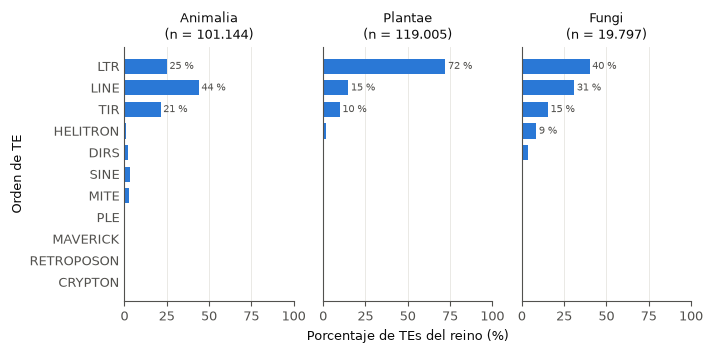

In [2]:
fig1, tabla1 = figura1(db, "../figuras/fig1_composicion_reino")
display(tabla1)

**Esperado:** Plantae dominado por LTR (~72 %); Animalia por LINE (~44 %), seguido de LTR (~25 %) y TIR (~21 %); Fungi con LTR (~40 %) y LINE (~31 %), y la mayor proporción de HELITRON (~9 %).

*Interpretación:* Cada reino tiene un perfil distinto: las plantas están dominadas por retrotransposones LTR, los animales por LINE y Fungi es intermedio, con la mayor proporción de HELITRON. Se usan porcentajes porque los reinos tienen tamaños muy distintos (Plantae 119.005 TEs, Fungi 19.797); con conteos, Fungi casi no se vería. Los porcentajes describen las bibliotecas de PanTEon, no la fracción del genoma.

## Figura 2. Longitud de los TEs por orden

,count,min,25%,50%,75%,max,mean
te_orden,,,,,,,
SINE,3634,81,190,254,312,500,253
CRYPTON,112,108,192,282,316,2367,303
MITE,3456,100,246,346,423,500,336
RETROPOSON,113,195,719,1159,1720,3463,1291
TIR,36471,100,468,1341,2992,9991,2034
PLE,344,107,980,2208,3429,8809,2212
LINE,68382,500,1807,3279,4544,6000,3241
HELITRON,5075,100,1190,3371,6315,14819,4095
DIRS,2933,109,3235,5143,5748,6998,4414


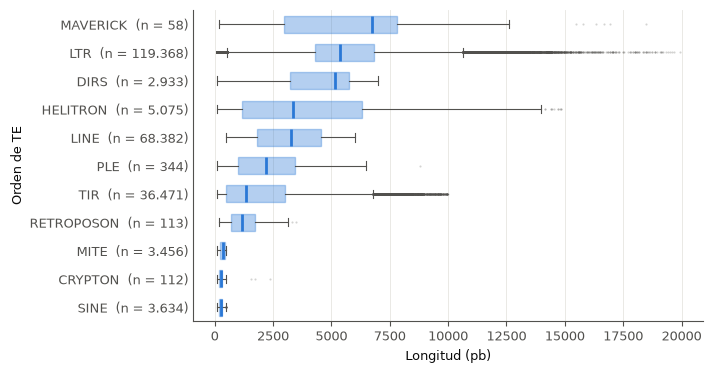

In [3]:
fig2, resumen2 = figura2(db, "../figuras/fig2_longitud_orden")
display(resumen2)

**Resultado.** Longitud global de 81 a 19.926 pb (mediana 4.259 pb). Más cortos: SINE (mediana 254 pb), CRYPTON (282) y MITE (346). Más largos: MAVERICK (6.758), LTR (5.347; IQR 4.314–6.842) y DIRS (5.143). Intermedios: HELITRON (3.371), LINE (3.279), PLE (2.208), TIR (1.341) y RETROPOSON (1.159). Cortes exactos: SINE y MITE ≤ 500 pb; LINE de 500 a 6.000 pb; TIR < 10.000 pb; varios órdenes con mínimo de 100 pb.\n
    "\n",

**Interpretación.** La separación es coherente con la estructura de los TEs: SINE y MITE son no autónomos y cortos; LTR, DIRS y MAVERICK contienen genes completos y superan los 5 kb. Los cortes exactos no son biológicos: son los umbrales de longitud por superfamilia que PanTEon aplicó al construir la base, así que la figura describe las secuencias retenidas por esos filtros y no la longitud natural de cada orden. CRYPTON merece cautela: su mediana (282 pb) es muy baja para elementos que codifican una recombinasa, lo que sugiere fragmentos. La superposición entre HELITRON, LINE y PLE muestra que la longitud sola no basta para clasificar un TE. Guardar `longitud` precalculada permite esta consulta con una proyección de dos campos, sin leer las secuencias."

In [11]:
from pymongo import MongoClient

cliente= MongoClient("mongodb://localhost:27017", serverSelectionTimeoutMS=3000)
print(cliente.admin.command("ping"))

db= cliente["panteon"]

{'ok': 1.0}


[{'_id': 'Animalia', 'gc': 44.8583772}]


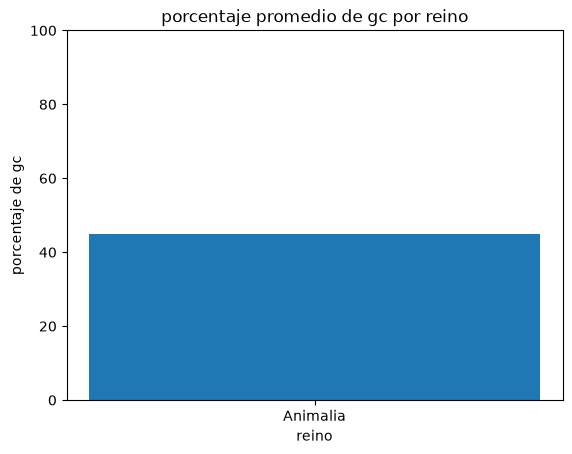

In [12]:
import matplotlib.pyplot as plt

resultados=list(db.secuencias.aggregate([
    {"$lookup":{"from":"especies","localField":"especie","foreignField":"especie","as":"sp"}},
    {"$unwind":"$sp"},
    {"$group":{"_id":"$sp.reino","gc":{"$avg":"$porcentaje_gc"}}},
    {"$sort":{"_id":1}}
]))

print(resultados)

reinos=[]
promedios=[]

for d in resultados:
    reinos.append(d["_id"])
    promedios.append(d["gc"])

plt.bar(reinos,promedios)
plt.title("porcentaje promedio de gc por reino")
plt.xlabel("reino")
plt.ylabel("porcentaje de gc")
plt.ylim(0,100)
plt.show()

In [16]:
print(list(db.secuencias.aggregate([
    {"$lookup":{"from":"especies","localField":"especie","foreignField":"especie","as":"sp"}},
    {"$unwind":"$sp"},
    {"$group":{"_id":"$sp.reino","cantidad":{"$sum":1}}}
])))

[{'_id': 'Animalia', 'cantidad': 2000}]


## `Figura 4`          Heatmap

`Desiciones:`

-Se promedia la frecuencia por secuencia, no los conteos brutos. Así una secuencia larga no pesa más que una corta.

-$ifNull(..., 0): como solo guardaste los k-mers presentes, un 2-mer ausente cuenta como frecuencia 0, no como dato faltante.

se imprimen las secuencias por orden y el control (debe sumar 1)

In [2]:
import sys
sys.path.append("..")            # el notebook está en notebooks/

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
from pymongo import MongoClient

from src.figuras_c import frecuencias_2mers_por_orden, DINUC

db = MongoClient("mongodb://localhost:27017/")["panteon_prueba"]

df = frecuencias_2mers_por_orden(db)
mat = df[DINUC]
print(df["n"])
print(df[DINUC].sum(axis=1).round(3).unique())   # debe mostrar [1.]

te_orden
CRYPTON          112
DIRS            2933
HELITRON        5075
LINE           68382
LTR           119368
MAVERICK          58
MITE            3456
PLE              344
RETROPOSON       113
SINE            3634
TIR            36471
Name: n, dtype: int64
[1.]


## ``Construccion del HeatMap``

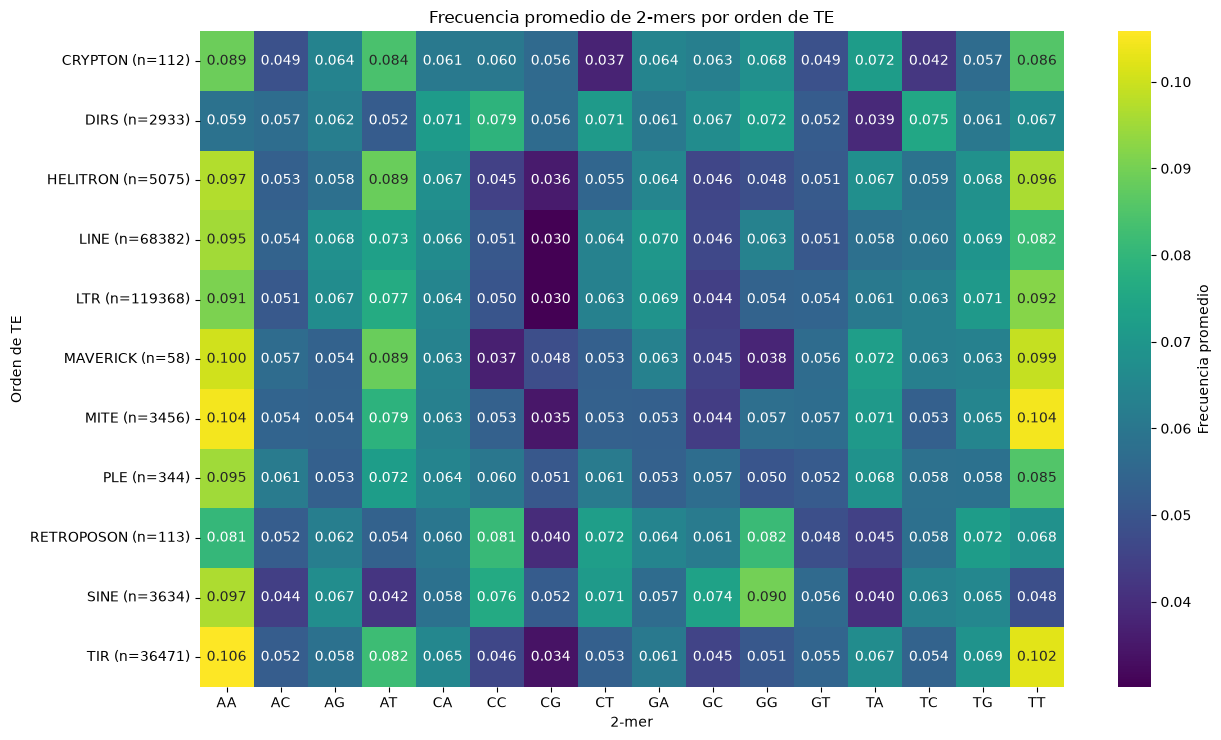

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

mat = df[DINUC]
etiquetas = [f"{o} (n={n})" for o, n in df["n"].items()]

fig, ax = plt.subplots(figsize=(13, 0.5 * len(mat) + 2))
sns.heatmap(mat, annot=True, fmt=".3f", cmap="viridis",
            yticklabels=etiquetas, cbar_kws={"label": "Frecuencia promedio"}, ax=ax)
ax.set_title("Frecuencia promedio de 2-mers por orden de TE")
ax.set_xlabel("2-mer"); ax.set_ylabel("Orden de TE")
plt.tight_layout()
Path("../figuras").mkdir(exist_ok=True)
plt.savefig("../figuras/heatmap_2mers_orden.png", dpi=200)
plt.show()

## ``Agrupacion de ordenes parecidos``


[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


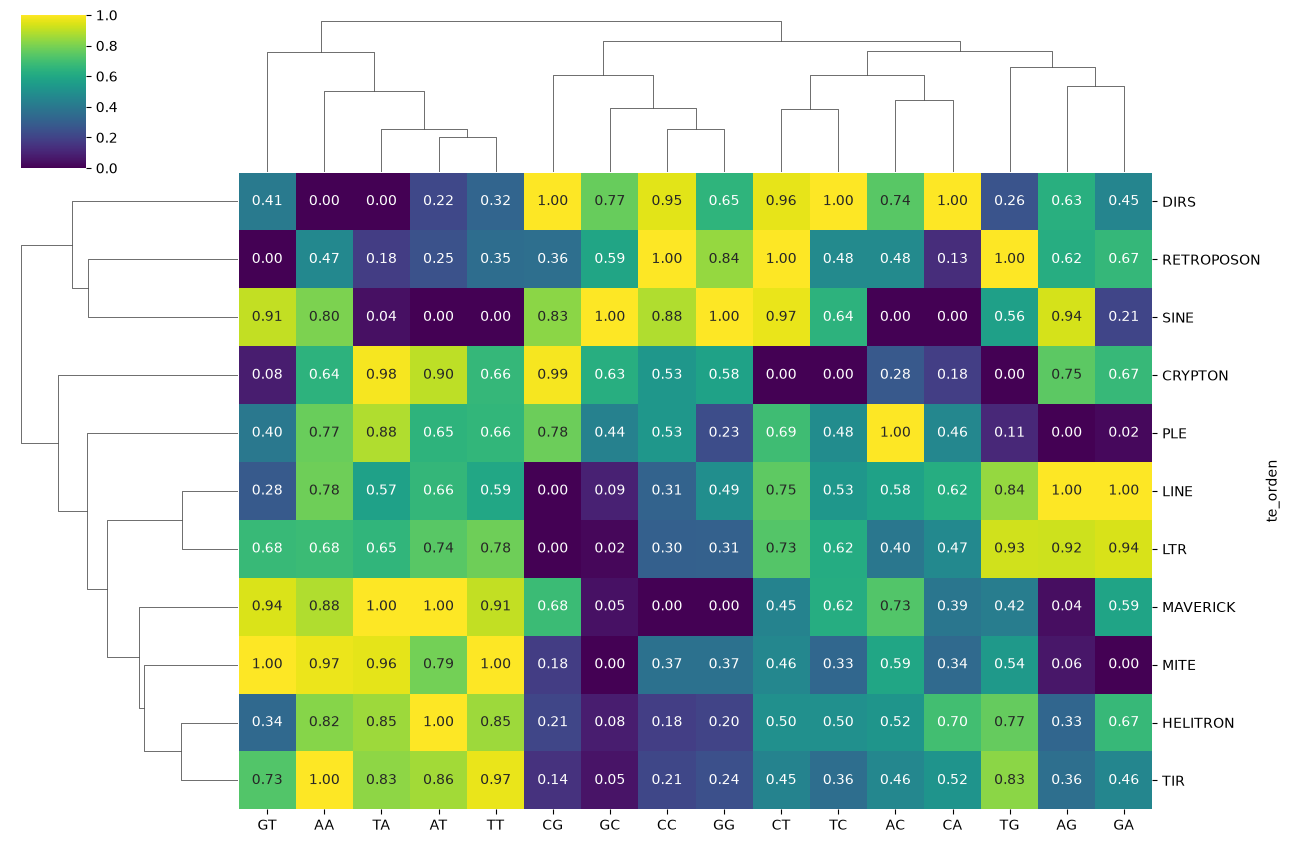

In [3]:
%pip install scipy
g = sns.clustermap(mat, cmap="viridis", annot=True, fmt=".2f",
                   standard_scale=1,          # normaliza cada 2-mer para ver diferencias relativas
                   figsize=(13, 0.5 * len(mat) + 3))
g.savefig("../figuras/clustermap_2mers_orden.png", dpi=200)

## ``Media numerica de similutud``

In [5]:
from scipy.spatial.distance import pdist, squareform
import numpy as np

dist = pd.DataFrame(squareform(pdist(mat)), index=mat.index, columns=mat.index)
triu = dist.where(np.triu(np.ones(dist.shape, bool), k=1))   # k=1 excluye la diagonal
pares = triu.stack().dropna().sort_values()

print("Más parecidos:\n", pares.head(5).round(4))
print("Más distintos:\n", pares.tail(5).round(4))

Más parecidos:
 te_orden  te_orden
HELITRON  TIR         0.0151
MITE      TIR         0.0159
LINE      LTR         0.0168
HELITRON  MAVERICK    0.0222
          LTR         0.0235
dtype: float64
Más distintos:
 te_orden  te_orden
MITE      SINE        0.0947
DIRS      MAVERICK    0.0969
SINE      TIR         0.0975
HELITRON  SINE        0.0977
MAVERICK  SINE        0.1076
dtype: float64


## `¿Que nos dicen las tablas y que podemos analizar de las figuras?`

``Qué dicen``

SINE aparece en 4 de los 5 pares más distintos, siempre frente a los órdenes del bloque AA/TT alto (MAVERICK, HELITRON, TIR, MITE). Es el orden más atípico de la base, y eso coincide con lo que se ve en el heatmap: TT=0,048 y AT=0,042 en SINE frente a 0,082 a 0,104 en esos órdenes. La distancia más grande (0,1076) es unas 7 veces la más pequeña (0,0151).

DIRS-MAVERICK es el único par de los más distintos que no incluye a SINE. Es coherente con lo anterior: DIRS comparte con SINE un perfil más rico en CC/GG y pobre en AT, y MAVERICK está en el extremo opuesto (AA=0,100, TT=0,099).

``Interpretación final``

Las distancias euclidianas entre perfiles de 2-mers confirman dos extremos. Los órdenes más parecidos son HELITRON-TIR (0,0151), MITE-TIR (0,0159) y LINE-LTR (0,0168). Los más distintos son MAVERICK-SINE (0,1076), HELITRON-SINE (0,0977) y SINE-TIR (0,0975). SINE interviene en 4 de los 5 pares más alejados, por lo que es el orden con el perfil más singular: TT y AT bajos (0,048 y 0,042) y GG y CC altos (0,090 y 0,076). El otro par extremo, DIRS-MAVERICK (0,0969), refleja la misma oposición entre perfiles ricos en G+C y perfiles dominados por AA/TT. La separación entre extremos es unas 7 veces la distancia entre los órdenes más parecidos, así que los perfiles de dinucleótidos sí distinguen unos órdenes de otros.